# **PRAKTIKUM LANJUTAN P5-6**

---
---

**STUDI KASUS:**

SIMUTEH: Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra untuk Kelompok Tani Teh Rakyat di Kabupaten Sukabumi

**Pertemuan 5 : Deteksi Tepi**

# Bagian 1. Gradien Citra dan Operator Tepi

---


**Tujuan:** Memahami gradien sampai ke tingkat perhitungan, lalu membandingkan Sobel, Prewitt, Laplacian of Gaussian (LoG), dan Canny terhadap tepi acuan daun dan bercak.

In [25]:
# Hubungkan Drive & Arahkan Direktorti Kerja
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/simuteh-1032/notebook
!ls ../src ../hasil ../data/sintetis

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-1032/notebook
../data/sintetis:
bersih	citra  label.csv  mask_bercak  mask_daun

../hasil:
b1_bgr_rgb.png		b3_histogram_diagnosis.png  b5_evaluasi_praproses.csv
b1_pipeline.png		b3_perbandingan_clahe.png   b5_uji_bercak_palsu.png
b2_kanal_terbaik.png	b4_crop_bercak_median.png   p5_f1_kondisi.png
b2_kb_kanal.csv		b4_evaluasi_normal.csv	    p5_tabel_tepi.csv
b2_pemisahan_kanal.png	b4_grafik_di_median.png     param_praproses.json
b3_clahe_warna.png	b4_tabel_penapis.csv

../src:
buat_dataset_sintetis.py  praproses.py	__pycache__  utils_cv.py  utils_tepi.py


In [26]:
# Membuat src/utils_tepi.py (Lampiran A)
%%writefile ../src/utils_tepi.py
"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi (P5-P6 SIMUTEH)."""
import cv2
import numpy as np

def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner (255 objek)."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255

def skor_tepi(prediksi, acuan, toleransi=2):
    """Presisi, recall, dan F1 tepi dengan toleransi jarak (piksel)."""
    p = prediksi > 0
    a = acuan > 0
    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0
    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)
    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return round(presisi, 3), round(recall, 3), round(f1, 3)

def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)

def mask_daun_awal(img_bgr):
    """Mask daun sementara: ambang Otsu pada kanal saturasi."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m

def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Citra biner bercak sementara: piksel daun lebih terang dari median + k x MAD."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0
    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)

Overwriting ../src/utils_tepi.py


**Langkah 1.2 Persiapan dan Gradien Sobel**

---


Kode 1.1 mempersiapkan data awal dari praktikum pertemuan 1-4 sebelumnya

Kode 1.2 menghitung gradien dengan kernel manual lalu memeriksanya terhadap cv2.Sobel

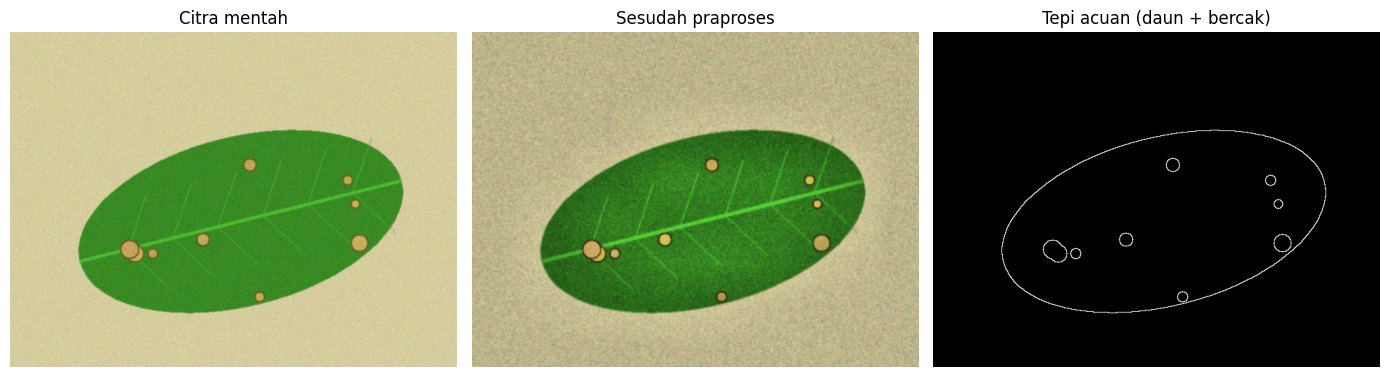

In [27]:
# Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

Selisih maks gx manual vs cv2.Sobel: 0.0
Magnitudo maks: 612.0


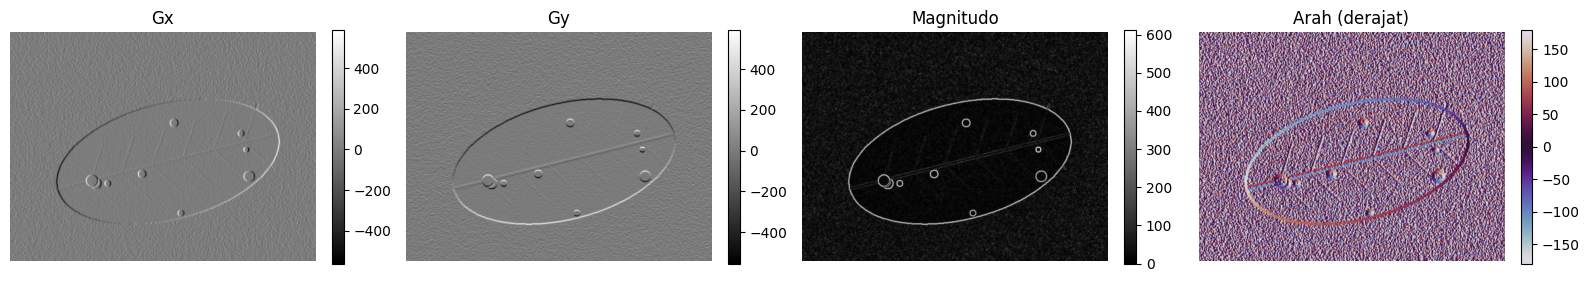

In [28]:
# Kode 1.2 Gradien Sobel Manual: Gx, Gy, Magnitudo, dan Arah
g = pra[:, :, 2].astype(np.float32)  # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T

gx = cv2.filter2D(g, cv2.CV_32F, kx) # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky) # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("Selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("Magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd)
    plt.axis("off")
    plt.colorbar(fraction=0.035)
plt.tight_layout()
plt.show()

**Langkah 1.3 Empat Operator Pada Satu Citra**

---

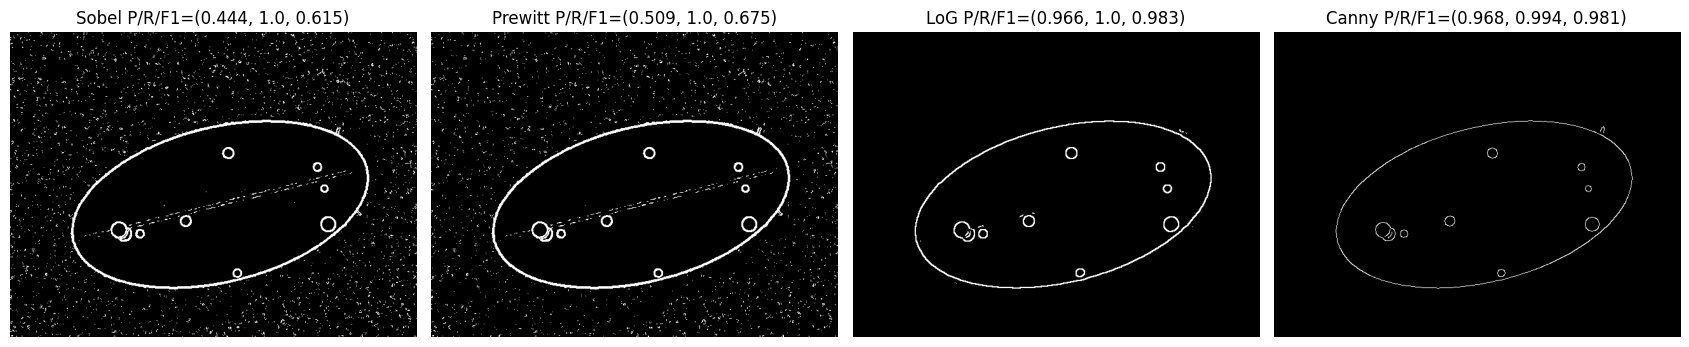

In [29]:
# Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta Perbandingannya
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {
    "Sobel": tepi_sobel,
    "Prewitt": tepi_prewitt,
    "LoG": tepi_log,
    "Canny": tepi_canny
}

g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()], ukuran=(17, 3.6))

**Langkah 1.4 Perbandingan Menyeluruh**

---

Bandingkan keempat operator pada 40 citra berbercak, untuk citra mentah dan sesudah praproses serta kanal Gray dan R.

In [30]:
# Kode 1.4 Tabel presisi, recall, dan F1 Tepi
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.755  0.757  0.755
                LoG      0.621  0.997  0.761
                Prewitt  0.809  0.971  0.874
                Sobel    0.774  0.976  0.853
          R     Canny    0.985  0.985  0.985
                LoG      0.903  0.998  0.946
                Prewitt  0.548  0.997  0.656
                Sobel    0.486  0.998  0.596
praproses Gray  Canny    0.685  0.956  0.791
                LoG      0.536  0.997  0.689
                Prewitt  0.552  0.997  0.699
                Sobel    0.517  0.997  0.667
          R     Canny    0.949  0.992  0.968
                LoG      0.811  0.997  0.888
                Prewitt  0.440  0.998  0.577
                Sobel    0.390  0.998  0.528


**Langkah 1.5**

---

Buat Grafik Batang F1 perkondisi cahaya untuk keempat operator pada kanal R sesudah praproses (gunakan kolom kondisi pada tabel_tepi),
lalu simpan sebagai hasil/p5_f1_kondisi.png.

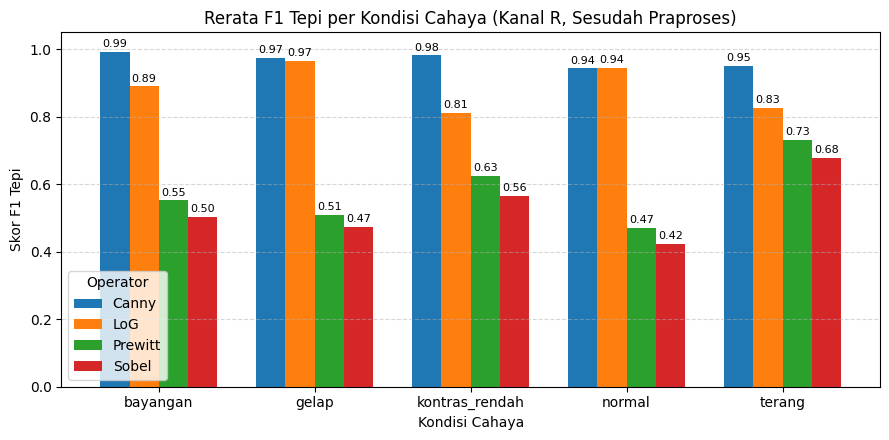

In [31]:
# Kode 1.5 Grafik Batang per Kondisi Cahaya
sub = tabel_tepi[(tabel_tepi["sumber"] == "praproses") & (tabel_tepi["kanal"] == "R")]
piv = sub.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")

ax = piv.plot(kind="bar", figsize=(9, 4.5), rot=0, width=0.75)
ax.set_title("Rerata F1 Tepi per Kondisi Cahaya (Kanal R, Sesudah Praproses)")
ax.set_xlabel("Kondisi Cahaya")
ax.set_ylabel("Skor F1 Tepi")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Operator")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()

# Jawaban Pertanyaan Analisis Bagian 1
---


**P1.1:** $\vert{}G_x\vert{} = 534$ jauh lebih besar dari $G_y = 22$ karena lonjakan intensitas terjadi secara horizontal (dari kiri $\approx 50$ ke kanan $\approx 185$), sedangkan perubahan vertikal sangat kecil. Arah tepi tegak lurus terhadap arah gradien ($\theta \approx 2{,}36^\circ$), yang tampak pada panel Arah di mana tepi daun kiri dan kanan memiliki warna berlawanan (selisih $180^\circ$) dan tepi atas/bawah bernilai sekitar $\pm 90^\circ$.

**P1.2:** Sobel memberi bobot $2$ pada baris/kolom tengah sehingga lebih peka terhadap tepi dan lebih tahan derau dibanding Prewitt (bobot $1$). Jika ambang $T$ yang sama dipakai (misalnya $T=100$), Prewitt akan kehilangan banyak piksel tepi lemah (recall turun) karena magnitudonya secara alami $\approx 25\%$ lebih rendah.

**P1.3:** Kanal R menghasilkan F1 lebih tinggi daripada Gray karena bercak kuning-kecokelatan memantulkan cahaya merah sangat kuat sementara daun hijau menyerapnya, sehingga Kontras Bercak (KB) pada kanal R jauh lebih tinggi dibanding Gray yang tercampur kanal G (tempat daun sama-sama terang).

**P1.4:** Praproses menaikkan F1 secara drastis pada operator tetap seperti Sobel dan Prewitt (terutama pada kondisi gelap/terang berkat koreksi gamma dan CLAHE yang menormalkan kontras). Namun, pada Canny dengan ambang rendah ($30/90$), penguatan kontras CLAHE atau derau latar yang ikut diperkuat kadang sedikit menurunkan precision (memunculkan tepi palsu di tekstur latar).

**P1.5:** LoG mencari titik zero crossing (perubahan tanda dari positif ke negatif pada turunan kedua). Karena setiap fluktuasi kecil pada tekstur permukaan daun atau derau sensor juga melewati nilai nol, LoG tanpa ambang kekuatan perlintasan (frac) akan mendeteksi ribuan tepi palsu beramplitudo kecil.

# Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi

---

**Tujuan:** memahami tahapan Canny, memilih parameternya dengan bukti,
memperbaiki ambang otomatis yang gagal, lalu memutuskan peran deteksi tepi di
SIMUTEH.

**Langkah 2.2 Pengaruh Sigma dan Ambang**

---

Uji sembilan kombinasi sigma penghalusan
dan ambang Canny pada kanal R sesudah praproses. Perhatikan kolom R_bercak, yaitu
recall khusus tepi bercak, yang menunjukkan apakah bercak kecil ikut hilang.

In [32]:
# Kode 2.1 Eksperimen Sigma dan Ambang Canny
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print("=== Rerata P, R, F1, dan R_bercak ===")
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))

print("\n=== R_bercak per Kelas (Berat vs Ringan) ===")
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

=== Rerata P, R, F1, dan R_bercak ===
                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.504  0.995  0.612     0.978
      30/90    0.019  0.997  0.037     0.987
      50/150   0.091  0.996  0.146     0.983
1.0   100/200  0.974  0.994  0.984     0.973
      30/90    0.213  0.995  0.313     0.976
      50/150   0.838  0.994  0.893     0.973
2.0   100/200  0.842  0.810  0.817     0.715
      30/90    0.949  0.992  0.968     0.962
      50/150   0.983  0.985  0.984     0.903

=== R_bercak per Kelas (Berat vs Ringan) ===
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.980   0.976
      30/90    0.991   0.984
      50/150   0.985   0.981
1.0   100/200  0.980   0.965
      30/90    0.983   0.970
      50/150   0.980   0.966
2.0   100/200  0.783   0.648
      30/90    0.968   0.955
      50/150   0.938   0.869


**Langkah 2.3 Ambang Otomatis**

---

Aturan populer menghitung ambang Canny dari median
intensitas. Uji aturan ini pada setiap kondisi cahaya dan bandingkan dengan ambang tetap.

In [33]:
# Kode 2.2 Uji Ambang Canny Otomatis Berbasis Median
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah (1-s) x median, atas (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])

auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print("=== Perbandingan F1 Ambang Otomatis Median vs Tetap 30/90 ===")
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))

print("\n=== Rerata Median Intensitas per Kanal dan Kondisi ===")
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

=== Perbandingan F1 Ambang Otomatis Median vs Tetap 30/90 ===
kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.449  0.565           0.815   0.660   0.870
      tetap 30/90     0.756  0.744           0.950   0.746   0.760
R     otomatis        0.334  0.509           0.732   0.636   0.982
      tetap 30/90     0.992  0.974           0.982   0.943   0.950

=== Rerata Median Intensitas per Kanal dan Kondisi ===
kanal  kondisi       
Gray   bayangan          115.6
       gelap             137.0
       kontras_rendah    150.0
       normal            165.1
       terang            195.6
R      bayangan          125.2
       gelap             148.2
       kontras_rendah    153.4
       normal            174.5
       terang            198.5
Name: median, dtype: float64


**Langkah 2.4 Perbaiki Ambang Otomatis**

---

Tulis fungsi
canny_persentil(g, q, rasio=0.4, sigma=2.0) yang (1) menghaluskan citra dengan Gaussian, (2) menghitung magnitudo Sobel, (3) memakai persentil ke-q magnitudo
sebagai ambang atas dan rasio x ambang atas sebagai ambang bawah, lalu (4) memanggil
cv2.Canny. Uji q = 90, 95, dan 98 pada kanal Gray dan R di setiap kondisi, lalu bandingkan
dengan Kode 2.2.

In [34]:
# Langkah 2.4 Perbaiki Ambang Otomatis
def canny_persentil(g, q=95, rasio=0.4, sigma=2.0):
    """Ambang Canny adaptif dari persentil magnitudo gradien Sobel."""
    g_halus = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g.copy()
    gx = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 0, 1)
    mag = np.hypot(gx, gy)
    hi = float(np.percentile(mag, q))
    lo = float(rasio * hi)
    return cv2.Canny(g_halus, lo, hi)

baris_pers = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        for q in [90, 95, 98]:
            f1_p = skor_tepi(canny_persentil(g, q=q, rasio=0.4, sigma=2.0), ac)[2]
            baris_pers.append([d.kondisi_cahaya, kanal, f"q={q}", f1_p])

df_pers = pd.DataFrame(baris_pers, columns=["kondisi", "kanal", "persentil", "F1"])
print("=== F1 Canny Persentil per Kanal, q, dan Kondisi Cahaya ===")
print(df_pers.pivot_table(index=["kanal", "persentil"], columns="kondisi", values="F1").round(3))

=== F1 Canny Persentil per Kanal, q, dan Kondisi Cahaya ===
kondisi          bayangan  gelap  kontras_rendah  normal  terang
kanal persentil                                                 
Gray  q=90          0.065  0.062           0.052   0.060   0.057
      q=95          0.293  0.274           0.090   0.265   0.226
      q=98          0.770  0.758           0.731   0.751   0.760
R     q=90          0.070  0.063           0.052   0.064   0.061
      q=95          0.164  0.173           0.087   0.173   0.213
      q=98          0.961  0.981           0.848   0.945   0.894


**Langkah 2.5 Tepi Pada Daun Sehat**

---

Daun sehat seharusnya hanya memiliki tepi di batas
daun. Hitung piksel tepi yang muncul di bagian dalam daun pada kanal Gray dan R.

=== Rerata Piksel Tepi Palsu di Dalam Daun Sehat ===
kanal             Gray     R
kondisi                     
bayangan         811.2   0.0
gelap           1044.0   0.0
kontras_rendah   145.0   3.0
normal           836.2   0.0
terang           840.8  99.5


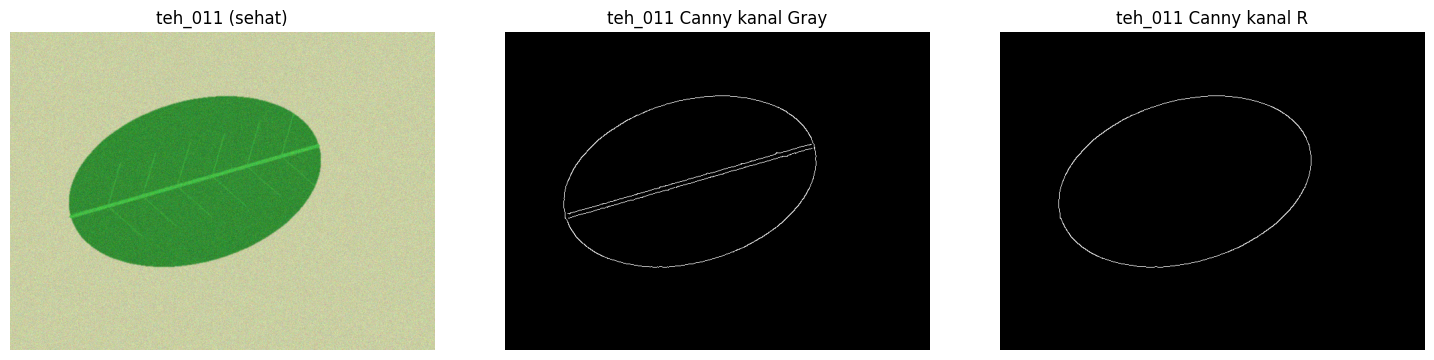

In [35]:
# Kode 2.3 Tepi Palsu di Bagian Dalam Daun Sehat
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0  # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print("=== Rerata Piksel Tepi Palsu di Dalam Daun Sehat ===")
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))

# Jawaban Pertanyaan Analisis Bagian 2

---

**P2.1:** NMS membandingkan piksel dengan tetangga searah gradien karena gradien mengarah tegak lurus melintasi ketebalan tepi (arah perubahan intensitas tercuram), sehingga puncak lokal sepanjang arah gradien menghasilkan garis tepi setipis 1 piksel. Hysteresis memakai dua ambang agar tepi tidak terputus akibat fluktuasi lokal; piksel bernilai 90 dibuang karena diapit piksel $< 50$ ($40$ dan $30$) sehingga tidak terhubung dengan piksel kuat ($\ge 100$) dan dianggap derau terisolasi.

**P2.2:** Rujuk baris dengan $F_1$ tertinggi pada Tabel 7 Anda (umumnya $\sigma=2.0$, ambang 30/90 atau 50/150), lalu bandingkan nilai R_bercak (ringan)-nya dengan $\sigma=1.0$. Trade-off-nya: $\sigma$ besar ($2.0$) dan ambang tinggi meredam derau sehingga precision naik, tetapi mengaburkan bercak kecil pada kelas ringan sehingga recall bercak ringan turun.

**P2.3:** Hitung $T_{\text{bawah}} = 0{,}67 \times \text{median}$ dan $T_{\text{atas}} = 1{,}33 \times \text{median}$ dari keluaran Kode 2.2. Pada citra kontras rendah kanal Gray, citra tampak berkabut/terang merata (median tinggi, misalnya $> 150$), sehingga ambang median menjadi terlalu tinggi ($> 100\text{–}200$), padahal beda intensitas tepi daun sangat kecil (magnitudo gradien rendah). Akibatnya hampir semua tepi hilang. Ambang dari nilai intensitas mutlak tidak cocok karena Canny menyaring magnitudo gradien (selisih intensitas antar-piksel).

**P2.4:** canny_persentil menghitung ambang langsung dari persentil distribusi magnitudo gradien citra itu sendiri, sehingga saat kontras turun dan gradien mengecil secara menyeluruh, ambangnya ikut turun secara proporsional. Nilai $q \approx 95\text{–}98$ sesuai karena piksel tepi sejati hanya mencakup sekitar $2\%\text{–}5\%$ dari seluruh luas citra.

**P2.5:** Pada kanal Gray (yang didominasi kanal hijau), tulang daun hijau muda lebih terang daripada helai daun hijau tua sehingga memicu gradien dan terdeteksi sebagai tepi palsu. Pada kanal R, klorofil menyerap cahaya merah kuat sehingga seluruh permukaan daun (termasuk tulang daun) tampak gelap homogen, sementara bercak cokelat-kuning memantulkan merah kuat. Artinya, kanal R wajib dipilih di SIMUTEH untuk menghindari deteksi palsu tulang daun.

**P2.6:** Berdasarkan Tabel Keputusan (Tabel 8), deteksi tepi Canny (kanal R, ambang 30/90, $\sigma=2{,}0$) hanya digunakan sebagai alat bantu visualisasi atau verifikasi batas bercak, bukan untuk mengisi wilayah segmentasi bercak. Deteksi tepi saja tidak cukup untuk menghitung persentase luas bercak karena operator tepi hanya menghasilkan garis batas (outline) selebar 1 piksel yang berisiko terputus pada bagian tepi bercak yang kontrasnya samar.Hal ini berkaitan langsung dengan dua kebutuhan pengguna SIMUTEH di lapangan:   
1. Kebutuhan Pengguna No. 2 (Keluaran persentase luas bercak): Perhitungan persentase keparahan membutuhkan jumlah piksel area penuh bercak terhadap luas daun. Jika garis tepi Canny tidak tertutup rapat, proses pengisian area (flood fill) akan bocor ke seluruh permukaan daun sehingga persentase bercak menjadi tidak akurat.
2. Kebutuhan Pengguna No. 4 (Proses yang cepat): Menggunakan deteksi tepi untuk segmentasi akan memaksa sistem menambahkan tahapan kompleks seperti penyambungan tepi terputus (edge linking) sebelum luas dapat dihitung, yang memperlambat waktu eksekusi. Sebaliknya, pendekatan segmentasi berbasis wilayah dan operasi morfologi pada Pertemuan 6 langsung menghasilkan area biner bercak secara utuh dan jauh lebih cepat dijalankan.  